In [ ]:
from google.colab import files
uploaded = files.upload()

Saving customer_complaints_dataset.xlsx to customer_complaints_dataset.xlsx


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Read the uploaded Excel file
file_name = list(uploaded.keys())[0]
df = pd.read_excel(file_name)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (500, 10)


,Complaint_ID,Date,Product,Customer_Text,Rating,Channel,Cleaned_Text,Category,Sentiment,Priority
0,C001,2026-01-01,Mobile,Order tracking has not updated in a week!,2,Email,order tracking has not updated in a week,Delivery,Negative,Medium
1,C002,2026-01-01,Mobile,Support resolved my issue in minutes!!,5,Social Media,support resolved my issue in minutes,Customer Service,Positive,Low
2,C003,2026-01-01,Internet,"Unable to install the latest update, error 504",2,Phone,unable to install the latest update error 504,Technical Issue,Negative,Medium
3,C004,2026-01-02,E-commerce,Refund credited only half of the amount,2,Email,refund credited only half of the amount,Refund,Negative,High
4,C005,2026-01-02,Laptop,Refund credited only half of the amount,2,App,refund credited only half of the amount,Refund,Negative,High


In [ ]:
print("Columns in the dataset:\n")

for i, column in enumerate(df.columns, start=1):
    print(i, ".", column)

Columns in the dataset:

1 . Complaint_ID
2 . Date
3 . Product
4 . Customer_Text
5 . Rating
6 . Channel
7 . Cleaned_Text
8 . Category
9 . Sentiment
10 . Priority


In [ ]:
print("Dataset Information:")
print("=" * 50)

df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Complaint_ID   500 non-null    object        
 1   Date           500 non-null    datetime64[ns]
 2   Product        500 non-null    object        
 3   Customer_Text  500 non-null    object        
 4   Rating         500 non-null    int64         
 5   Channel        500 non-null    object        
 6   Cleaned_Text   500 non-null    object        
 7   Category       500 non-null    object        
 8   Sentiment      500 non-null    object        
 9   Priority       500 non-null    object        
dtypes: datetime64[ns](1), int64(1), object(8)
memory usage: 39.2+ KB


In [ ]:
print("Missing values in each column:")
print("=" * 50)

print(df.isnull().sum())

Missing values in each column:
Complaint_ID     0
Date             0
Product          0
Customer_Text    0
Rating           0
Channel          0
Cleaned_Text     0
Category         0
Sentiment        0
Priority         0
dtype: int64


In [ ]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [ ]:
duplicate_ids = df["Complaint_ID"].duplicated().sum()

print("Duplicate Complaint IDs:", duplicate_ids)

Duplicate Complaint IDs: 0


In [ ]:
df.describe()

,Date,Rating
count,500,500.000000
mean,2026-04-28 15:53:16.799999744,2.654000
min,2026-01-01 00:00:00,1.000000
25%,2026-02-26 00:00:00,2.000000
50%,2026-04-28 12:00:00,2.000000
75%,2026-06-28 00:00:00,4.000000
max,2026-08-31 00:00:00,5.000000
std,NaN,1.343836


In [ ]:
category_counts = df["Category"].value_counts()
print(category_counts)

Category
Payment             78
Technical Issue     75
Product Quality     74
Delivery            68
Billing             61
Customer Service    56
Refund              52
Account Access      36
Name: count, dtype: int64


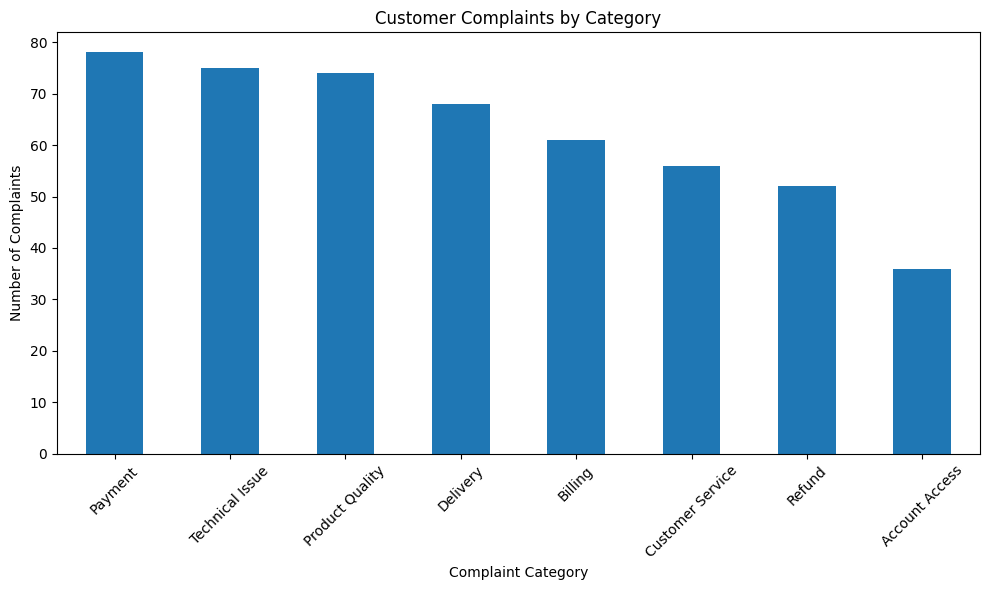

In [ ]:
plt.figure(figsize=(10, 6))

category_counts.plot(kind="bar")

plt.title("Customer Complaints by Category")
plt.xlabel("Complaint Category")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
sentiment_counts = df["Sentiment"].value_counts()
print(sentiment_counts)

Sentiment
Negative    276
Positive    136
Neutral      88
Name: count, dtype: int64


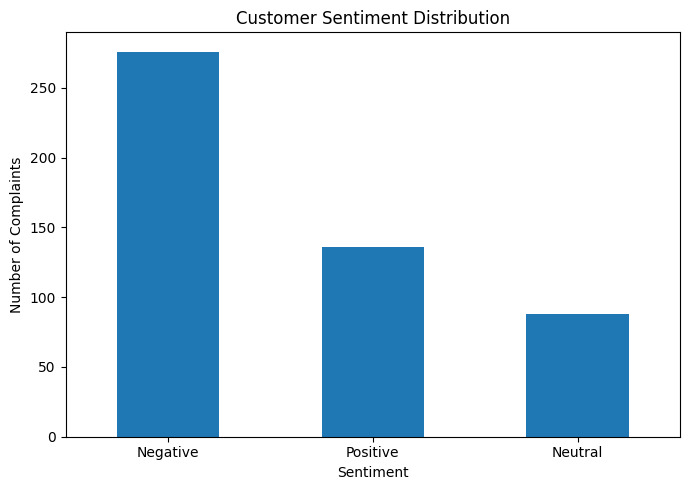

In [ ]:
plt.figure(figsize=(7, 5))

sentiment_counts.plot(kind="bar")

plt.title("Customer Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
priority_counts = df["Priority"].value_counts()

print(priority_counts)

Priority
Low       193
High      160
Medium    147
Name: count, dtype: int64


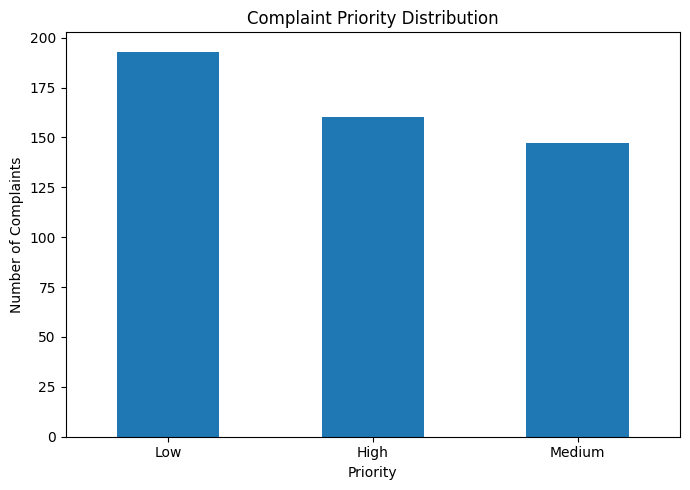

In [ ]:
plt.figure(figsize=(7, 5))

priority_counts.plot(kind="bar")

plt.title("Complaint Priority Distribution")
plt.xlabel("Priority")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
product_counts = df["Product"].value_counts()
print(product_counts)

Product
Mobile           133
Laptop            68
E-commerce        57
Internet          49
Bank Account      46
Insurance         39
Credit Card       32
Television        22
App               20
Headphones        19
Food Delivery     15
Name: count, dtype: int64


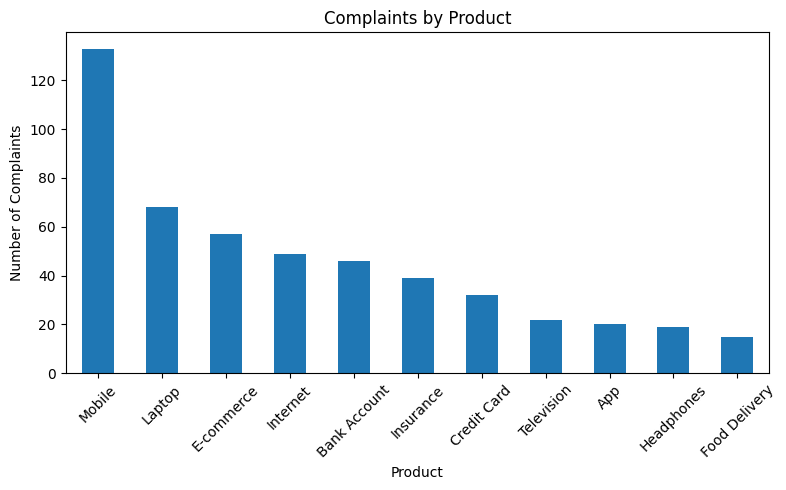

In [ ]:
plt.figure(figsize=(8, 5))

product_counts.plot(kind="bar")

plt.title("Complaints by Product")
plt.xlabel("Product")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
channel_counts = df["Channel"].value_counts()
print(channel_counts)

Channel
App             145
Website         110
Email            77
Phone            63
Chat             55
Social Media     50
Name: count, dtype: int64


In [ ]:
average_rating = (
    df.groupby("Category")["Rating"]
    .mean()
    .sort_values(ascending=False)
)

print(average_rating)

Category
Technical Issue     3.000000
Account Access      2.861111
Payment             2.769231
Product Quality     2.716216
Refund              2.615385
Billing             2.540984
Delivery            2.352941
Customer Service    2.339286
Name: Rating, dtype: float64


Rating
1    108
2    168
3     88
4     61
5     75
Name: count, dtype: int64


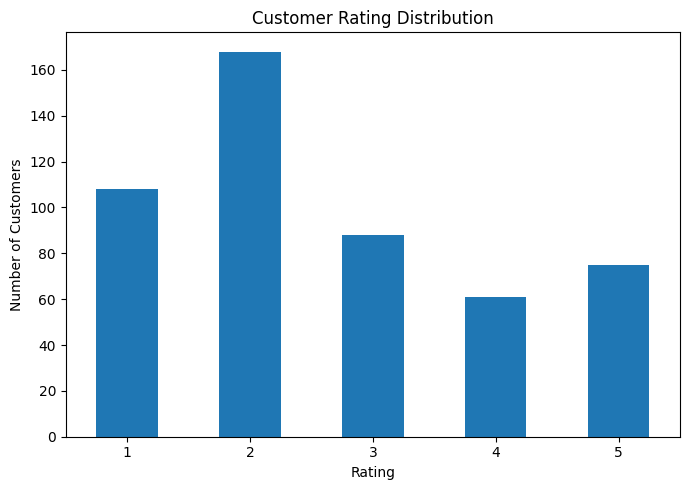

In [ ]:
rating_counts = df["Rating"].value_counts().sort_index()

print(rating_counts)

plt.figure(figsize=(7, 5))

rating_counts.plot(kind="bar")

plt.title("Customer Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
import re

def clean_text(text):
    text = str(text)
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df["Cleaned_Text"] = df["Customer_Text"].apply(clean_text)

df[["Customer_Text", "Cleaned_Text"]].head()

,Customer_Text,Cleaned_Text
0,Order tracking has not updated in a week!,order tracking has not updated in a week
1,Support resolved my issue in minutes!!,support resolved my issue in minutes
2,"Unable to install the latest update, error 504",unable to install the latest update error
3,Refund credited only half of the amount,refund credited only half of the amount
4,Refund credited only half of the amount,refund credited only half of the amount


In [ ]:
print(df["Cleaned_Text"].head(10))

0             order tracking has not updated in a week
1                 support resolved my issue in minutes
2            unable to install the latest update error
3              refund credited only half of the amount
4              refund credited only half of the amount
5          works fine though the camera is just decent
6                   refund was processed but took days
7    login is fast and the new fingerprint option i...
8             device stopped turning on after two days
9                  item delivered to the wrong address
Name: Cleaned_Text, dtype: object


In [ ]:
print(df["Category"].value_counts())

Category
Payment             78
Technical Issue     75
Product Quality     74
Delivery            68
Billing             61
Customer Service    56
Refund              52
Account Access      36
Name: count, dtype: int64


In [ ]:
print(df[["Customer_Text", "Cleaned_Text", "Category"]].head(20).to_string(index=False))

                                          Customer_Text                                          Cleaned_Text         Category
              Order tracking has not updated in a week!              order tracking has not updated in a week         Delivery
                 Support resolved my issue in minutes!!                  support resolved my issue in minutes Customer Service
         Unable to install the latest update, error 504             unable to install the latest update error  Technical Issue
                Refund credited only half of the amount               refund credited only half of the amount           Refund
                Refund credited only half of the amount               refund credited only half of the amount           Refund
           works fine, though the camera is just decent           works fine though the camera is just decent  Product Quality
                Refund was processed but took 10 days!!                    refund was processed but took days  

In [ ]:
print("Duplicate complaints:", df["Customer_Text"].duplicated().sum())

Duplicate complaints: 258


In [ ]:
print("Duplicate cleaned texts:", df["Cleaned_Text"].duplicated().sum())

Duplicate cleaned texts: 380


In [ ]:
print("Before removing duplicates:", df.shape)

df = df.drop_duplicates(subset=["Cleaned_Text"]).reset_index(drop=True)

print("After removing duplicates:", df.shape)

Before removing duplicates: (500, 10)
After removing duplicates: (120, 10)


In [ ]:
print(df["Category"].value_counts())

Category
Technical Issue     19
Product Quality     16
Payment             15
Customer Service    15
Account Access      14
Delivery            14
Billing             14
Refund              13
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_text = df["Cleaned_Text"]
y = df["Category"]

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train_text.shape)
print("Testing data:", X_test_text.shape)

Training data: (96,)
Testing data: (24,)


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()

X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

print("Training TF-IDF shape:", X_train.shape)
print("Testing TF-IDF shape:", X_test.shape)

Training TF-IDF shape: (96, 290)
Testing TF-IDF shape: (24, 290)


In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [ ]:
y_pred = model.predict(X_test)

print("Predictions completed!")
print(y_pred)

Predictions completed!
['Refund' 'Product Quality' 'Payment' 'Technical Issue' 'Customer Service'
 'Product Quality' 'Technical Issue' 'Account Access' 'Delivery'
 'Product Quality' 'Technical Issue' 'Technical Issue' 'Billing'
 'Customer Service' 'Refund' 'Payment' 'Product Quality'
 'Customer Service' 'Billing' 'Payment' 'Delivery' 'Technical Issue'
 'Account Access' 'Refund']


In [ ]:
from sklearn.metrics import accuracy_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="weighted")

print("Accuracy:", accuracy)
print("Accuracy percentage:", round(accuracy * 100, 2), "%")
print("F1 Score:", round(f1, 2))

Accuracy: 0.7916666666666666
Accuracy percentage: 79.17 %
F1 Score: 0.79


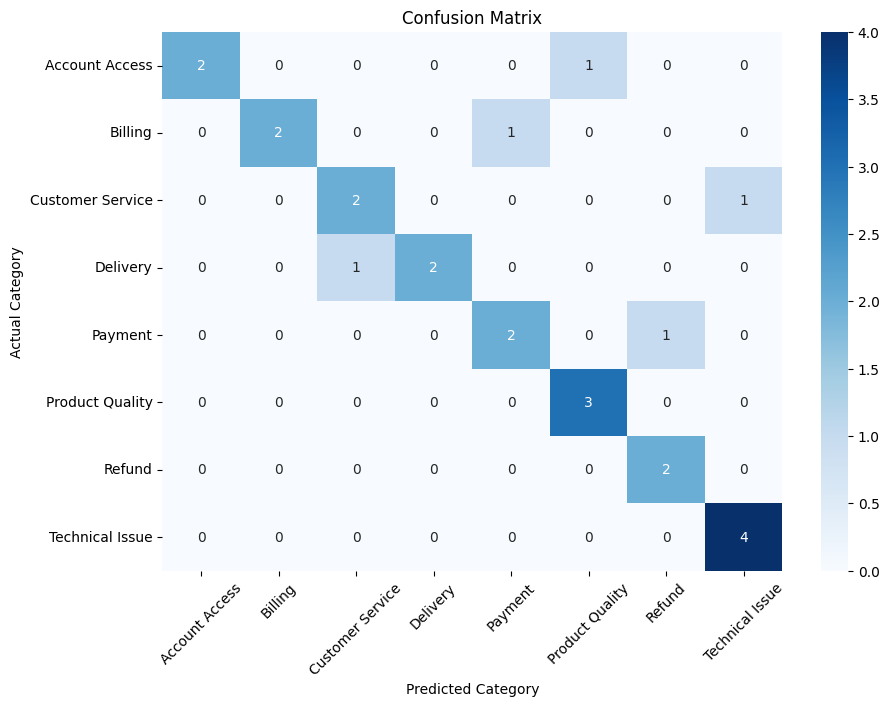

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

In [ ]:
new_complaint = [
    "My refund has not been credited to my account"
]

cleaned_complaint = [clean_text(new_complaint[0])]

complaint_tfidf = tfidf.transform(cleaned_complaint)

prediction = model.predict(complaint_tfidf)

print("New Complaint:", new_complaint[0])
print("Predicted Category:", prediction[0])

New Complaint: My refund has not been credited to my account
Predicted Category: Refund


In [ ]:
import sqlite3

connection = sqlite3.connect("complaints.db")

df.to_sql("complaints", connection, if_exists="replace", index=False)

print("Complaint data loaded into SQL database successfully!")

Complaint data loaded into SQL database successfully!


In [ ]:
query = """
SELECT *
FROM complaints
LIMIT 5;
"""

result = pd.read_sql_query(query, connection)

result

,Complaint_ID,Date,Product,Customer_Text,Rating,Channel,Cleaned_Text,Category,Sentiment,Priority
0,C001,2026-01-01 00:00:00,Mobile,Order tracking has not updated in a week!,2,Email,order tracking has not updated in a week,Delivery,Negative,Medium
1,C002,2026-01-01 00:00:00,Mobile,Support resolved my issue in minutes!!,5,Social Media,support resolved my issue in minutes,Customer Service,Positive,Low
2,C003,2026-01-01 00:00:00,Internet,"Unable to install the latest update, error 504",2,Phone,unable to install the latest update error,Technical Issue,Negative,Medium
3,C004,2026-01-02 00:00:00,E-commerce,Refund credited only half of the amount,2,Email,refund credited only half of the amount,Refund,Negative,High
4,C006,2026-01-03 00:00:00,Laptop,"works fine, though the camera is just decent",3,Email,works fine though the camera is just decent,Product Quality,Neutral,Medium


In [ ]:
query = """
SELECT COUNT(*) AS Total_Complaints
FROM complaints;
"""

result = pd.read_sql_query(query, connection)

result

,Total_Complaints
0,120


In [ ]:
query = """
SELECT Category, COUNT(*) AS Complaint_Count
FROM complaints
GROUP BY Category
ORDER BY Complaint_Count DESC;
"""

result = pd.read_sql_query(query, connection)

result

,Category,Complaint_Count
0,Technical Issue,19
1,Product Quality,16
2,Payment,15
3,Customer Service,15
4,Delivery,14
5,Billing,14
6,Account Access,14
7,Refund,13


In [ ]:
query = """
SELECT Category,
       ROUND(AVG(Rating), 2) AS Average_Rating
FROM complaints
GROUP BY Category
ORDER BY Average_Rating DESC;
"""

result = pd.read_sql_query(query, connection)

result

,Category,Average_Rating
0,Technical Issue,2.95
1,Billing,2.71
2,Refund,2.69
3,Payment,2.67
4,Delivery,2.50
5,Account Access,2.50
6,Product Quality,2.31
7,Customer Service,2.27


In [ ]:
query = """
SELECT COUNT(*) AS High_Priority_Complaints
FROM complaints
WHERE Priority = 'High';
"""

result = pd.read_sql_query(query, connection)

result

,High_Priority_Complaints
0,43


In [ ]:
query = """
SELECT Product, COUNT(*) AS Complaint_Count
FROM complaints
GROUP BY Product
ORDER BY Complaint_Count DESC;
"""

result = pd.read_sql_query(query, connection)

result

,Product,Complaint_Count
0,Mobile,37
1,Laptop,19
2,Internet,14
3,E-commerce,12
4,Insurance,10
5,Bank Account,9
6,Television,6
7,Credit Card,5
8,App,4
9,Headphones,2


In [ ]:
query = """
SELECT Channel, COUNT(*) AS Complaint_Count
FROM complaints
GROUP BY Channel
ORDER BY Complaint_Count DESC;
"""

result = pd.read_sql_query(query, connection)

result

,Channel,Complaint_Count
0,App,33
1,Website,30
2,Email,22
3,Chat,17
4,Phone,11
5,Social Media,7


In [ ]:
query = """
SELECT COUNT(*) AS Negative_Complaints
FROM complaints
WHERE Sentiment = 'Negative';
"""

result = pd.read_sql_query(query, connection)

result

,Negative_Complaints
0,64


In [ ]:
connection.close()

print("SQL connection closed.")

SQL connection closed.


In [ ]:
df.to_excel("Final_Complaint_Analysis.xlsx", index=False)

print("Final dataset exported successfully!")

Final dataset exported successfully!
